In [24]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (9,6)
plt.rcParams["font.size"] = 12

**Load Results**

In [25]:
df = pd.read_csv("../results/metrics.csv")

df.head()

,Image,Resolution,Payload,Payload_Size(Bytes),AES_Encrypt_Time(s),Dynamic_XOR_Time(s),Embedding_Time(s),Sender_Total_Time(s),Extraction_Time(s),XOR_Recovery_Time(s),AES_Decrypt_Time(s),Receiver_Total_Time(s),PSNR,MSE,NPCR,Entropy
0,aircraft_1024.png,1024x1024,100B.txt,100,0.000755,0.000221,0.002491,0.003467,0.000162,0.000149,0.000065,0.000375,86.405557,0.000149,0.014877,6.676904
1,aircraft_1024.png,1024x1024,1KB.txt,1024,0.000114,0.002016,0.002596,0.004726,0.001405,0.001277,0.000069,0.002751,77.033465,0.001287,0.128746,6.676903
2,aircraft_1024.png,1024x1024,250B.txt,250,0.000082,0.000411,0.000850,0.001343,0.000363,0.000326,0.000068,0.000757,83.043355,0.000323,0.032266,6.676904
3,aircraft_1024.png,1024x1024,2KB.txt,2048,0.000071,0.003422,0.004787,0.008280,0.002715,0.002548,0.000064,0.005327,73.954545,0.002616,0.261593,6.676914
4,aircraft_1024.png,1024x1024,4KB.txt,4096,0.000086,0.006848,0.009202,0.016136,0.005951,0.005411,0.000068,0.011430,70.972041,0.005198,0.519848,6.676924


**Payload Sizes**

In [26]:
sorted(df["Payload_Size(Bytes)"].unique())

[np.int64(100),
 np.int64(250),
 np.int64(500),
 np.int64(1024),
 np.int64(2048),
 np.int64(4096)]

**Image Name and Resolutions**

In [27]:
df["Image_Type"] = df["Image"].str.extract(r"([A-Za-z]+)")
df["Resolution"] = df["Resolution"].astype(str)

df.head()

,Image,Resolution,Payload,Payload_Size(Bytes),AES_Encrypt_Time(s),Dynamic_XOR_Time(s),Embedding_Time(s),Sender_Total_Time(s),Extraction_Time(s),XOR_Recovery_Time(s),AES_Decrypt_Time(s),Receiver_Total_Time(s),PSNR,MSE,NPCR,Entropy,Image_Type
0,aircraft_1024.png,1024x1024,100B.txt,100,0.000755,0.000221,0.002491,0.003467,0.000162,0.000149,0.000065,0.000375,86.405557,0.000149,0.014877,6.676904,aircraft
1,aircraft_1024.png,1024x1024,1KB.txt,1024,0.000114,0.002016,0.002596,0.004726,0.001405,0.001277,0.000069,0.002751,77.033465,0.001287,0.128746,6.676903,aircraft
2,aircraft_1024.png,1024x1024,250B.txt,250,0.000082,0.000411,0.000850,0.001343,0.000363,0.000326,0.000068,0.000757,83.043355,0.000323,0.032266,6.676904,aircraft
3,aircraft_1024.png,1024x1024,2KB.txt,2048,0.000071,0.003422,0.004787,0.008280,0.002715,0.002548,0.000064,0.005327,73.954545,0.002616,0.261593,6.676914,aircraft
4,aircraft_1024.png,1024x1024,4KB.txt,4096,0.000086,0.006848,0.009202,0.016136,0.005951,0.005411,0.000068,0.011430,70.972041,0.005198,0.519848,6.676924,aircraft


**Avereage Results**

In [28]:
payload_avg = (
    df.groupby("Payload_Size(Bytes)")
      .mean(numeric_only=True)
      .reset_index()
)

payload_avg

,Payload_Size(Bytes),AES_Encrypt_Time(s),Dynamic_XOR_Time(s),Embedding_Time(s),Sender_Total_Time(s),Extraction_Time(s),XOR_Recovery_Time(s),AES_Decrypt_Time(s),Receiver_Total_Time(s),PSNR,MSE,NPCR,Entropy
0,100,0.000100,0.000202,0.000443,0.000745,0.000174,0.000153,0.000051,0.000378,77.591462,0.003032,0.303227,7.399837
1,250,0.000053,0.000476,0.000678,0.001207,0.000370,0.000350,0.000051,0.000771,73.968320,0.006949,0.694931,7.399916
2,500,0.000060,0.000843,0.001231,0.002134,0.000721,0.000645,0.000053,0.001419,70.972639,0.013883,1.388337,7.399926
3,1024,0.000061,0.001713,0.002375,0.004150,0.001406,0.001309,0.000060,0.002775,67.918189,0.028015,2.801470,7.400160
4,2048,0.000054,0.003502,0.004822,0.008377,0.002961,0.002686,0.000075,0.005722,64.900165,0.056192,5.619214,7.400410
5,4096,0.000064,0.007341,0.009107,0.016512,0.006051,0.005646,0.000072,0.011768,61.930935,0.110877,11.087710,7.401087


**PSNR vs Payload**

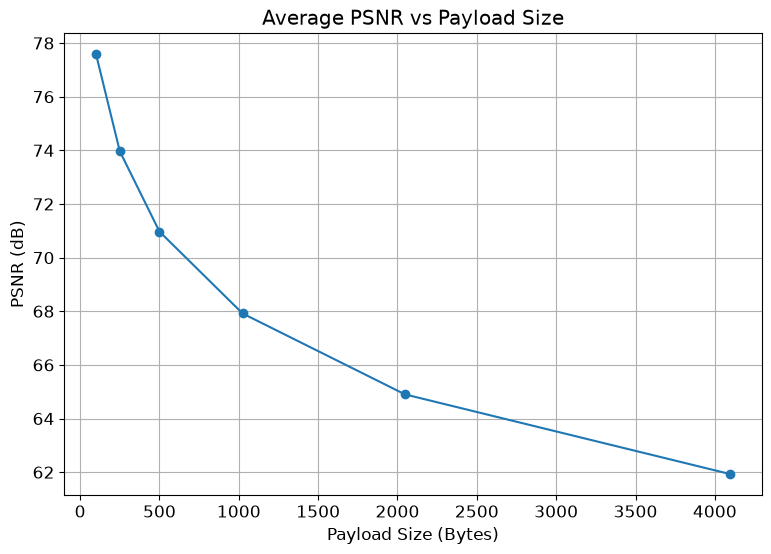

In [29]:
plt.plot(
    payload_avg["Payload_Size(Bytes)"],
    payload_avg["PSNR"],
    marker="o"
)

plt.xlabel("Payload Size (Bytes)")
plt.ylabel("PSNR (dB)")
plt.title("Average PSNR vs Payload Size")

plt.grid(True)

plt.show()

**MSE vs Payload**

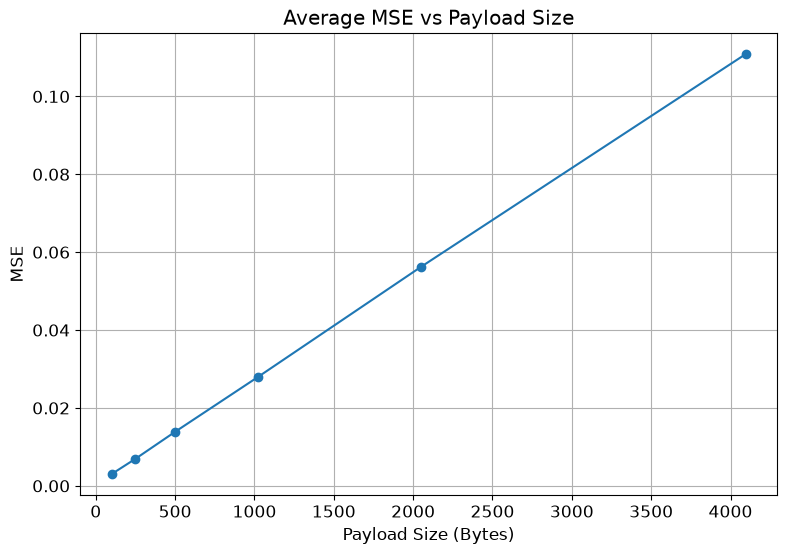

In [30]:
plt.plot(
    payload_avg["Payload_Size(Bytes)"],
    payload_avg["MSE"],
    marker="o"
)

plt.xlabel("Payload Size (Bytes)")
plt.ylabel("MSE")
plt.title("Average MSE vs Payload Size")

plt.grid(True)

plt.show()

**NCPR vs Payload**

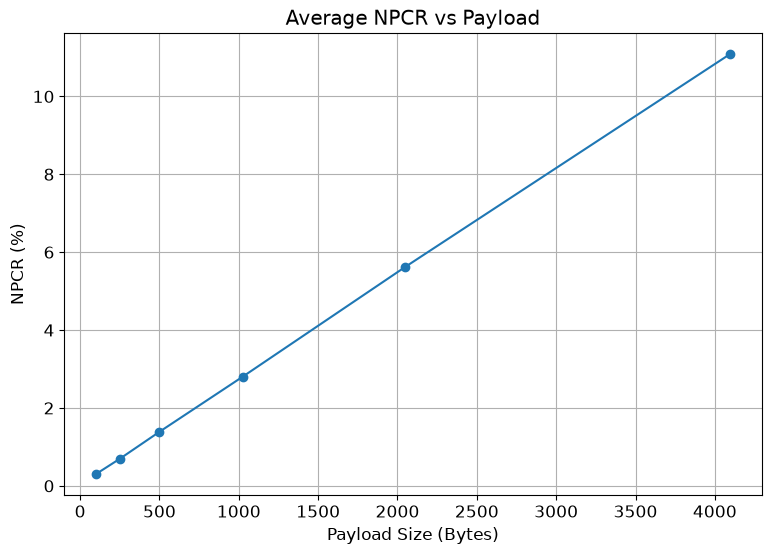

In [31]:
plt.plot(
    payload_avg["Payload_Size(Bytes)"],
    payload_avg["NPCR"],
    marker="o"
)

plt.xlabel("Payload Size (Bytes)")
plt.ylabel("NPCR (%)")
plt.title("Average NPCR vs Payload")

plt.grid(True)

plt.show()

**Entropy vs Payload**

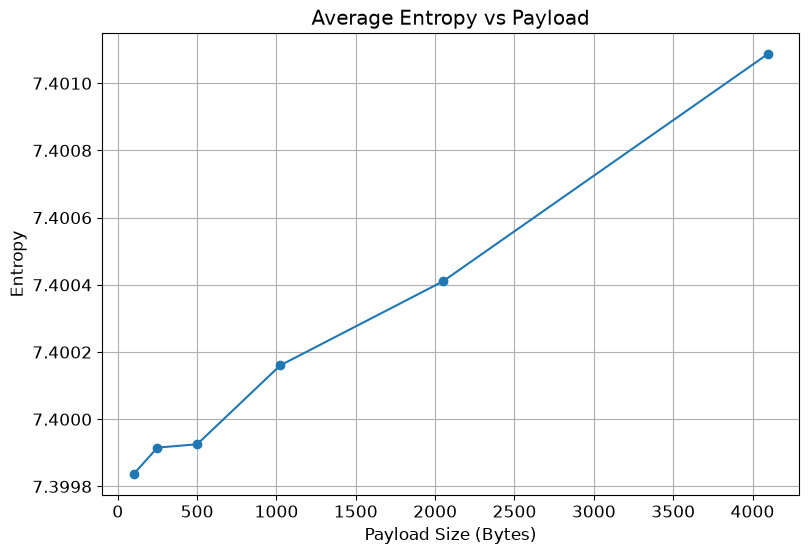

In [32]:
plt.plot(
    payload_avg["Payload_Size(Bytes)"],
    payload_avg["Entropy"],
    marker="o"
)

plt.xlabel("Payload Size (Bytes)")
plt.ylabel("Entropy")
plt.title("Average Entropy vs Payload")

plt.grid(True)

plt.show()

**Sender Time vs Payload**

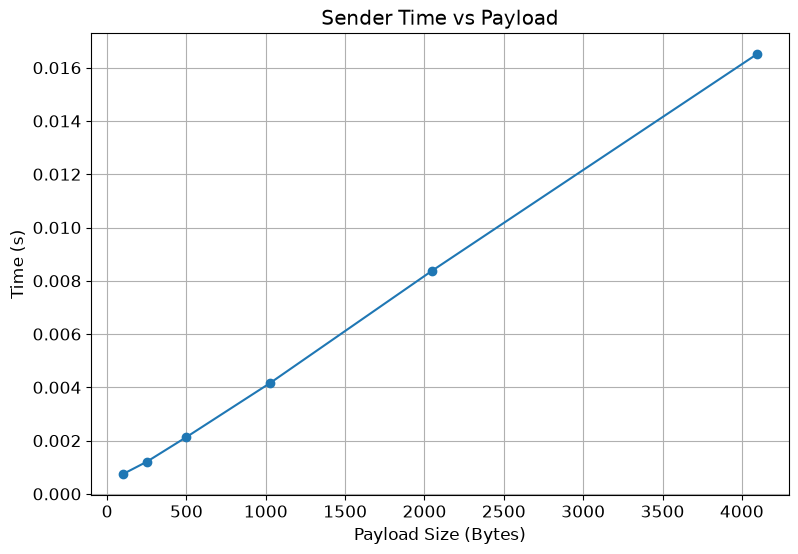

In [33]:
plt.plot(
    payload_avg["Payload_Size(Bytes)"],
    payload_avg["Sender_Total_Time(s)"],
    marker="o"
)

plt.xlabel("Payload Size (Bytes)")
plt.ylabel("Time (s)")
plt.title("Sender Time vs Payload")

plt.grid(True)

plt.show()

**Reciver Time vs Payload**

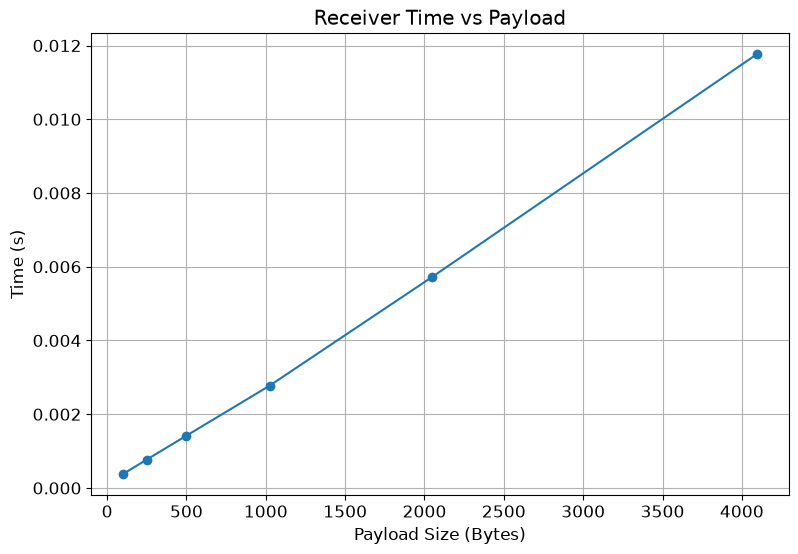

In [34]:
plt.plot(
    payload_avg["Payload_Size(Bytes)"],
    payload_avg["Receiver_Total_Time(s)"],
    marker="o"
)

plt.xlabel("Payload Size (Bytes)")
plt.ylabel("Time (s)")
plt.title("Receiver Time vs Payload")

plt.grid(True)

plt.show()